# Hands-on Lab: Vision–Language Models

**Before you do anything else:** go to **Runtime → Change runtime type → T4 GPU**, then run **Step 0** right away. It downloads two models and takes 2–4 minutes. Read the lab manual while it runs.

You only need to edit the lines marked `# ✏️ EDIT`. You do not need to write new code.

| Step | What you do | Time |
|---|---|---|
| 0 | Load the models | 0–5 min |
| 1 | CLIP: zero-shot classification | 5–20 min |
| 2 | VLM: ask questions about images | 20–30 min |
| 3 | Break the VLM | 30–40 min |
| 4 | Fill in the worksheet | 40–50 min |

## Step 0 — Load the models (run this first!)

In [1]:
!pip -q install -U transformers accelerate

import torch, requests, textwrap
from io import BytesIO
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
from transformers import CLIPModel, CLIPProcessor, AutoProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device, "(if this says cpu, change the runtime to T4 GPU and run again)")

# --- Model 1: CLIP (contrastive image-text model) ---
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_proc  = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# --- Model 2: SmolVLM (a small generative VLM) ---
try:
    from transformers import AutoModelForImageTextToText as VLMClass
except ImportError:
    from transformers import AutoModelForVision2Seq as VLMClass
VLM_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"
vlm_proc  = AutoProcessor.from_pretrained(VLM_ID)
vlm_model = VLMClass.from_pretrained(
    VLM_ID, torch_dtype=torch.float16 if device == "cuda" else torch.float32
).to(device)
print("Both models loaded ✔")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 105.1 MB/s eta 0:00:00
Running on: cuda (if this says cpu, change the runtime to T4 GPU and run again)


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.02GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

Both models loaded ✔


### Helper functions (just run this cell)

In [2]:
def load_image(src):
    """Load an image from a URL or a file path."""
    if str(src).startswith("http"):
        r = requests.get(src, headers={"User-Agent": "Mozilla/5.0"}, timeout=20)
        return Image.open(BytesIO(r.content)).convert("RGB")
    return Image.open(src).convert("RGB")

def show(img, title=""):
    plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off"); plt.title(title); plt.show()

def clip_classify(img, labels, prefix="a photo of "):
    """Score an image against a list of text labels with CLIP."""
    texts = [prefix + l for l in labels]
    inputs = clip_proc(text=texts, images=img, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        out = clip_model(**inputs)
    probs = out.logits_per_image.softmax(dim=1)[0].cpu().numpy()
    show(img)
    for l, p in sorted(zip(labels, probs), key=lambda x: -x[1]):
        print(f"{p*100:6.1f}%  {'█' * int(p * 40)}  {l}")

def ask_vlm(img, question, max_new_tokens=80):
    """Ask SmolVLM a question about an image."""
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": question}]}]
    prompt = vlm_proc.apply_chat_template(messages, add_generation_prompt=True)
    inputs = vlm_proc(text=prompt, images=[img], return_tensors="pt").to(device)
    with torch.no_grad():
        ids = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    answer = vlm_proc.batch_decode(ids[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0]
    show(img)
    print("Q:", question)
    print("A:", textwrap.fill(answer.strip(), 90))

def _font(size):
    for f in ["/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
              "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf"]:
        try: return ImageFont.truetype(f, size)
        except OSError: pass
    return ImageFont.load_default()

def make_dots(n, seed=0):
    """An image with exactly n circles."""
    import random; random.seed(seed)
    img = Image.new("RGB", (448, 448), "white"); d = ImageDraw.Draw(img); placed = []
    while len(placed) < n:
        x, y = random.randint(30, 418), random.randint(30, 418)
        if all((x-a)**2 + (y-b)**2 > 45**2 for a, b in placed):
            placed.append((x, y)); d.ellipse([x-18, y-18, x+18, y+18], fill=random.choice(["red", "blue", "green", "orange"]))
    return img

def make_left_right(left="red square", right="blue circle"):
    """Two shapes side by side, so we know which one is on the left."""
    img = Image.new("RGB", (448, 448), "white"); d = ImageDraw.Draw(img)
    def draw(desc, cx):
        color, shape = desc.split()
        box = [cx-60, 164, cx+60, 284]
        if shape == "square": d.rectangle(box, fill=color)
        elif shape == "circle": d.ellipse(box, fill=color)
        else: d.polygon([(cx, 164), (cx-60, 284), (cx+60, 284)], fill=color)
    draw(left, 112); draw(right, 336)
    return img

def make_text(text, size=40, rotate=0):
    """A white image with some text written on it."""
    img = Image.new("RGB", (448, 448), "white"); d = ImageDraw.Draw(img)
    d.multiline_text((20, 160), textwrap.fill(text, 18), fill="black", font=_font(size), spacing=8)
    return img.rotate(rotate, fillcolor="white")

CATS = "http://images.cocodataset.org/val2017/000000039769.jpg"
print("Helpers ready ✔")

Helpers ready ✔


## Step 1 — CLIP: zero-shot classification (5–20 min)

CLIP was trained with **contrastive learning**: it pulls matching image–text pairs together in a shared embedding space and pushes non-matching pairs apart. To classify, it computes the **cosine similarity** between the image embedding and each text label, then applies softmax.

No training happens here. *You* decide the classes, simply by writing text.

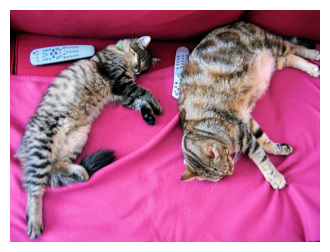

  68.1%  ███████████████████████████  sofa
  31.4%  ████████████  cat
   0.3%    car
   0.2%    dog


In [3]:
img = load_image(CATS)
labels = ["cat", "dog", "car", "sofa"]
clip_classify(img, labels)

**Task 1a.** Change the labels. Try `"two cats"` vs `"one cat"` vs `"three cats"`. Does CLIP know how many?

**Task 1b.** Change `prefix`. Compare `prefix="a photo of "` with `prefix=""`, and with `prefix="a drawing of "`. Record how the top score moves.

=== 1a: counting labels ===


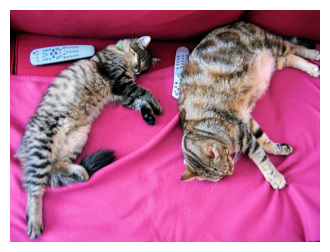

  74.0%  █████████████████████████████  two cats
  23.9%  █████████  three cats
   2.1%    one cat
=== 1b: prefix comparison ===

--- prefix = 'a photo of ' ---


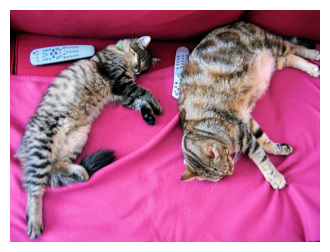

  68.1%  ███████████████████████████  sofa
  31.4%  ████████████  cat
   0.3%    car
   0.2%    dog

--- prefix = '' ---


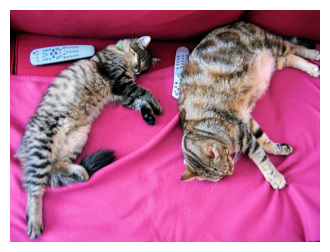

  73.8%  █████████████████████████████  sofa
  25.6%  ██████████  cat
   0.4%    car
   0.2%    dog

--- prefix = 'a drawing of ' ---


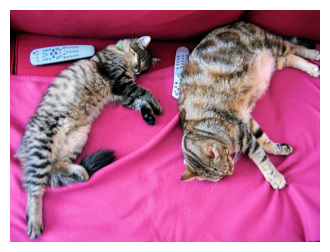

  74.2%  █████████████████████████████  sofa
  24.6%  █████████  cat
   0.9%    car
   0.3%    dog


In [4]:
img = load_image(CATS)
print("=== 1a: counting labels ===")
clip_classify(img, ["one cat", "two cats", "three cats"])

print("=== 1b: prefix comparison ===")
for p in ["a photo of ", "", "a drawing of "]:
    print(f"\n--- prefix = {p!r} ---")
    clip_classify(img, ["cat", "dog", "car", "sofa"], prefix=p)

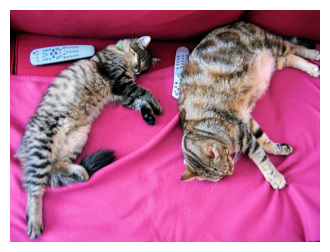

  74.0%  █████████████████████████████  two cats
  23.9%  █████████  three cats
   2.1%    one cat


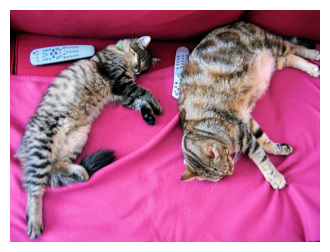

  73.8%  █████████████████████████████  sofa
  25.6%  ██████████  cat
   0.4%    car
   0.2%    dog


In [5]:
clip_classify(img, ["one cat", "two cats", "three cats"])
clip_classify(img, ["cat", "dog", "car", "sofa"], prefix="")

=== 1C ===


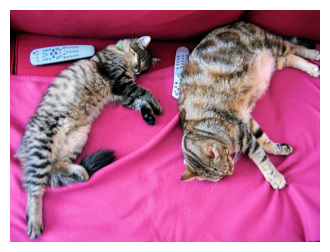

  68.0%  ███████████████████████████  sofa
  31.4%  ████████████  cat
   0.3%    car
   0.2%    dog
   0.1%    a spaceship


In [6]:
print("=== 1C ===")
clip_classify(img, ["cat", "dog", "car", "sofa", "a spaceship"])

## Step 2 — Ask a VLM questions (20–30 min)

SmolVLM is a **generative** VLM: a vision encoder turns the image into tokens, a projector maps them into the language model's embedding space, and a small LLM writes the answer, one token at a time.

Unlike CLIP, it can answer open questions. Start with a caption.

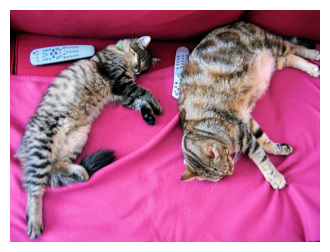

Q: Describe this image in one sentence.
A: Two tabby cats are sleeping on a pink blanket on a couch, next to a remote control.


In [7]:
ask_vlm(img, "Describe this image in one sentence.")

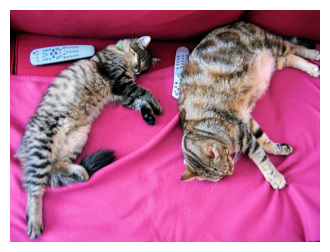

Q: What colour is the sofa?
A: The sofa is pink in colour.


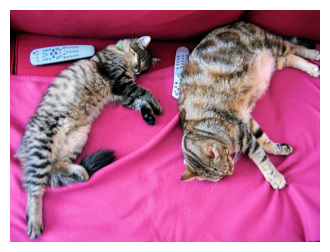

Q: What objects are lying next to the cats?
A: There are remotes in the image.


In [8]:
ask_vlm(img, "What colour is the sofa?")
ask_vlm(img, "What objects are lying next to the cats?")

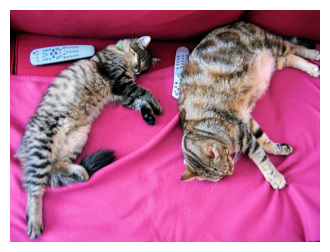

Q: Is the sofa pink or green?
A: The sofa is pink.


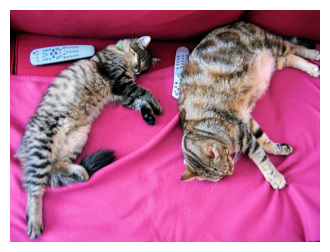

Q: What is the sofa's colour?
A: The sofa is pink in colour.


In [9]:
ask_vlm(img, "Is the sofa pink or green?")
ask_vlm(img, "What is the sofa's colour?")

## Step 3 — Break the VLM (30–40 min)

We generate the images ourselves, so **we know the correct answer**. Your team's job: find the clearest failure in each category, and then change *one thing* (the prompt or the image) to test your explanation of why it failed.

### 3a. Counting

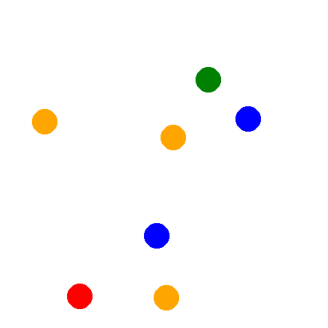

Q: How many circles are in this image? Answer with a number.
A: 5
TRUE ANSWER: 7


In [10]:
n = 7
ask_vlm(make_dots(n), "How many circles are in this image? Answer with a number.")
print("TRUE ANSWER:", n)

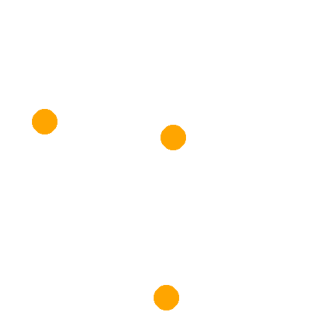

Q: How many circles are in this image? Answer with a number.
A: 3
TRUE ANSWER: 3 



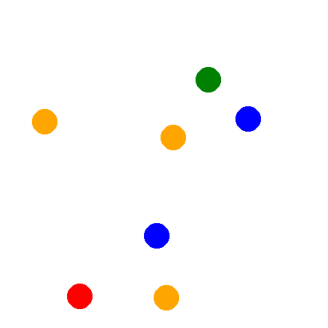

Q: How many circles are in this image? Answer with a number.
A: 5
TRUE ANSWER: 7 



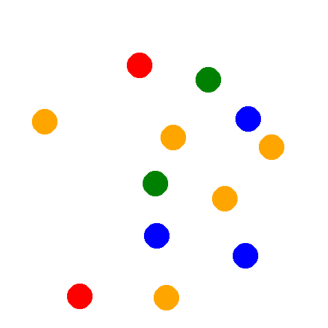

Q: How many circles are in this image? Answer with a number.
A: 9
TRUE ANSWER: 12 



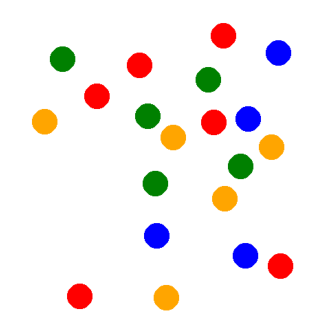

Q: How many circles are in this image? Answer with a number.
A: 15
TRUE ANSWER: 20 



In [11]:
for n in [3, 7, 12, 20]:
    ask_vlm(make_dots(n), "How many circles are in this image? Answer with a number.")
    print("TRUE ANSWER:", n, "\n")

### 3b. Left vs right

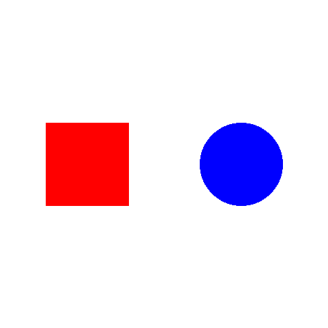

Q: Which shape is on the left: the square or the circle?
A: The square.
TRUE ANSWER: red square is on the left


In [12]:
ask_vlm(make_left_right("red square", "blue circle"),
        "Which shape is on the left: the square or the circle?")
print("TRUE ANSWER: red square is on the left")

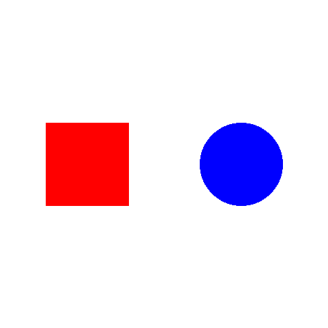

Q: Which shape is on the left: the square or the circle?
A: The square.
TRUE: square



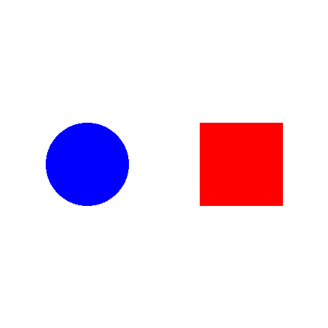

Q: Which shape is on the left: the square or the circle?
A: The circle.
TRUE: circle



In [13]:
ask_vlm(make_left_right("red square", "blue circle"), "Which shape is on the left: the square or the circle?")
print("TRUE: square\n")
ask_vlm(make_left_right("blue circle", "red square"), "Which shape is on the left: the square or the circle?")
print("TRUE: circle\n")

### 3c. Reading text (OCR)

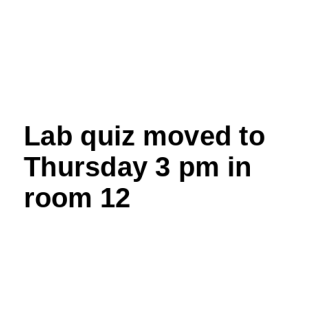

Q: What does the text in this image say?
A: Lab quiz moved to Thursday 3 pm in room 12.
TRUE ANSWER: Lab quiz moved to Thursday 3 pm in room 12


In [14]:
msg = "Lab quiz moved to Thursday 3 pm in room 12"
ask_vlm(make_text(msg, size=40, rotate=0), "What does the text in this image say?")
print("TRUE ANSWER:", msg)

size=40, rotate=0


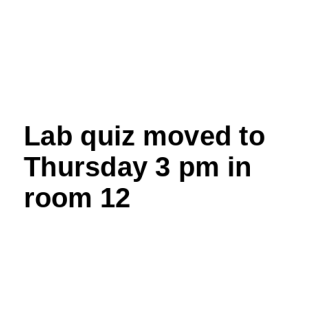

Q: What does the text in this image say?
A: Lab quiz moved to Thursday 3 pm in room 12.
TRUE: Lab quiz moved to Thursday 3 pm in room 12 

size=14, rotate=0


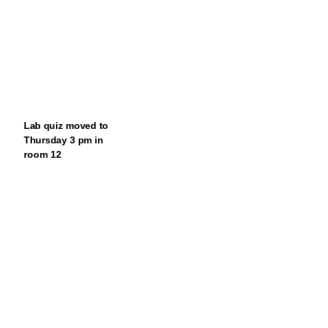

Q: What does the text in this image say?
A: The text in this image is a passage of text that appears to be a question or statement
related to a lab quiz. The passage is structured in a way that suggests it is part of a
larger document or text, possibly an academic or educational excerpt. The text is written
in a clear and legible font, and it appears to be in a formal style, possibly indicating a
discussion or analysis of a
TRUE: Lab quiz moved to Thursday 3 pm in room 12 

size=40, rotate=20


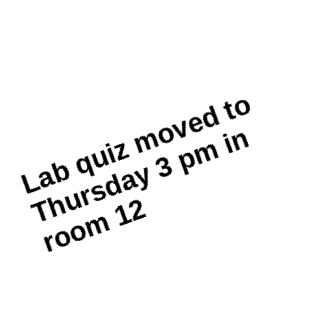

Q: What does the text in this image say?
A: Lab quiz moved to Thursday 3 pm in room 12
TRUE: Lab quiz moved to Thursday 3 pm in room 12 



In [15]:
msg = "Lab quiz moved to Thursday 3 pm in room 12"
for size, rot in [(40, 0), (14, 0), (40, 20)]:
    print(f"size={size}, rotate={rot}")
    ask_vlm(make_text(msg, size=size, rotate=rot), "What does the text in this image say?")
    print("TRUE:", msg, "\n")

### 3d. Hallucination — ask about something that is NOT there

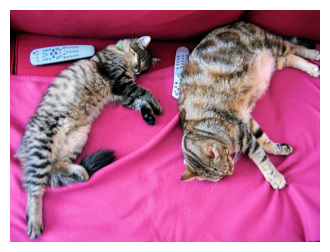

Q: What is the dog doing in this picture?
A: There is no dog present in the image.


In [16]:
ask_vlm(img, "What is the dog doing in this picture?")

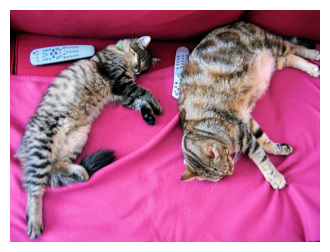

Q: What is the dog doing in this picture?
A: There is no dog present in the image.


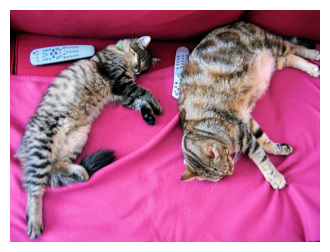

Q: Is there a dog in this picture?
A: No, there is no dog in this picture.


In [17]:
ask_vlm(img, "What is the dog doing in this picture?")
ask_vlm(img, "Is there a dog in this picture?")

### 3e. Your own photo
Take a photo on your phone (a whiteboard, a page of handwriting, a crowded desk), send it to the laptop (WhatsApp Web, email, or Google Drive), and upload it below.

Saving download.jpg to download.jpg


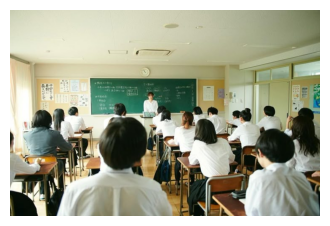

Q: Describe this image in detail.
A: The image depicts a classroom setting with several students seated at their desks facing a
teacher. The classroom is well-lit, with a large green chalkboard in the background, which
is partially visible. The chalkboard features a series of Chinese characters, which are
likely related to the subject matter of the lesson. The teacher, who is standing in front
of the class, is wearing a white shirt and black


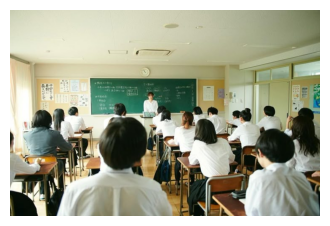

Q: what colour uniform are children wearing?.
A: White.


In [18]:
from google.colab import files
up = files.upload()
my_img = load_image(list(up.keys())[0])
ask_vlm(my_img, "Describe this image in detail.")
ask_vlm(my_img, "what colour uniform are children wearing?.")

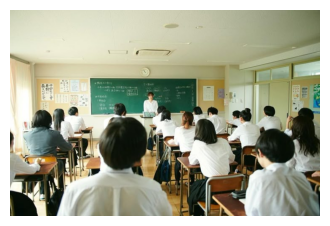

  52.9%  █████████████████████  a whiteboard
  22.1%  ████████  a desk
  17.6%  ███████  a person
   7.4%  ██  handwritten notes


In [19]:
# Bonus: does CLIP get it right where SmolVLM fails (or the other way round)?
clip_classify(my_img, ["a whiteboard", "handwritten notes", "a desk", "a person"])

## Step 4 — Worksheet (40–50 min)

Fill in the worksheet at the end of the lab manual. Your **best failure** (with your explanation and the test you ran) may be shown on the projector.